# Spoken Grammar Scoring Engine (second version, better score)
SHL Hiring Assessment 2026 - Veer Amol Singh (veer.amol636@gmail.com | veer23588@iiitd.ac.in)

| | RMSE | Pearson |
|---|---|---|
| Training data (final models predicting the clips they were trained on) | 0.2251 | 0.9754 |
| 5-fold cross-validation (clips the models never saw) | 0.4817 | 0.8801 |
| 5-fold cross-validation, weighted to the test set's batch mix | 0.5110 | |
| Baseline: always predict the mean | 1.0137 | |
| Public leaderboard (submission_v2.csv) | 0.3400 | |

The first submission which I had submitted in form as well, scored 0.3540 on the public leaderboard. Its CV RMSE on the same folds was 0.4963 (test-weighted 0.5355).

## Approach
1. Speech to text: Whisper turns each clip into text and keeps the mistakes and hesitations.
2. Text features: grammar models check the text for errors, and DeBERTa is fine-tuned to predict the score from it.
3. Audio features: WavLM and Whisper embeddings capture how fluently the person speaks, plus simple pause and pitch features.
4. Final model: ridge, SVR and LightGBM models on these features are combined into one score. Compared to the first submission, the models also know which recording batch a clip is from, and the 37 label-0 clips (not in the test set) are left out of training.

## Pipeline
```
                        +--> Whisper large-v3-turbo --> transcript + word timings
   audio.wav (16 kHz) --+                                   |
                        |                                   +--> speech statistics (rate, pauses, fillers, vocabulary)
                        |                                   +--> CoLA RoBERTa: sentence acceptability + embedding
                        |                                   +--> CoEdIT: grammar correction -> edits and error types
                        |                                   +--> Qwen2.5-0.5B surprisal, Qwen2.5-1.5B embedding
                        |                                   +--> DeBERTa-v3-base fine-tuned on the score
                        |
                        +--> WavLM-Large embedding + prosody features
                        +--> Whisper encoder embedding
                                                            |
            8 base models (ridge / SVR / LightGBM) + batch flags, same 5 folds --> out-of-fold predictions
                                                            |
                         non-negative linear stacker --> clip to [2, 5] --> submission_v2.csv
```

Transcription, the embeddings, the grammar models and DeBERTa need a GPU and take a few hours, so their outputs are saved in features/ and loaded here. Their code is shown in the notebook. Set RUN_HEAVY = True in the setup cell to recompute them.

## 0. Setup

In [1]:
import contextlib, json, os, platform, re, sys, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from lightgbm import LGBMRegressor
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from joblib import Parallel, delayed
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# ----- switches ---------------------------------------------------------------------------------------------
RUN_HEAVY = False   # True = recompute every cached feature from the raw audio (GPU, ~3 h)

# ----- paths & constants ------------------------------------------------------------------------------------
ROOT = Path.cwd()                       # run the notebook from the project folder
DATA_DIR = ROOT / "data" / "Dataset_Final"
FEAT_DIR = ROOT / "features"            # cached intermediate results
OUT_DIR = ROOT / "outputs"
V2_FEAT = FEAT_DIR / "v2"              # features added in v2
V2_OUT = OUT_DIR / "v2"                # v2 results, figures and the submission
for d in (FEAT_DIR, OUT_DIR, V2_FEAT, V2_OUT):
    d.mkdir(parents=True, exist_ok=True)
META_CSV = FEAT_DIR / "meta.csv"
TRANSCRIPTS = FEAT_DIR / "transcripts.jsonl"
SR, SEED, N_FOLDS = 16_000, 42, 5
assert (DATA_DIR / "train.csv").exists(), "run this notebook from the project folder (data/Dataset_Final must exist)"

# ----- plotting style: fixed-order categorical colours, thin marks, recessive grid --------------------------
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "legend.frameon": False, "font.size": 10,
})
def savefig(fig, name):
    fig.savefig(V2_OUT / f"{name}.png", dpi=110, bbox_inches="tight")

print(f"python {platform.python_version()} | torch {torch.__version__} | cuda available: {torch.cuda.is_available()}")

python 3.13.7 | torch 2.11.0+cu128 | cuda available: True


### helpers

In [2]:
# ----- helpers copied verbatim from src/common.py --------------------------------------------------------
def load_meta() -> pd.DataFrame:
    """One row per audio file: key, split, filename, label (NaN for test), duration, fold (-1 for test).

    Train and test folders reuse the same file names, so `key` = "<split>/<filename>" is the
    unique id used by every feature table.
    """
    if not META_CSV.exists():
        raise SystemExit("features/meta.csv not found - run src/01_prepare_data.py first.")
    return pd.read_csv(META_CSV)

def audio_path(split: str, filename: str) -> Path:
    return DATA_DIR / split / filename

def load_audio(path) -> np.ndarray:
    """Mono float32 waveform at 16 kHz."""
    import soundfile as sf

    wav, sr = sf.read(str(path), dtype="float32", always_2d=True)
    wav = wav.mean(axis=1)
    if sr != SR:
        import librosa

        wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
    return np.ascontiguousarray(wav, dtype=np.float32)

def load_transcripts(missing_ok: bool = False) -> dict[str, dict]:
    """Whisper output of step 2, keyed by `key`."""
    if not TRANSCRIPTS.exists():
        if missing_ok:
            return {}
        raise SystemExit("features/transcripts.jsonl not found - run src/02_transcribe.py first.")
    records = {}
    with open(TRANSCRIPTS, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rec = json.loads(line)
                records[rec["key"]] = rec
    return records

def get_device():
    import torch

    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def expose_cuda_dlls() -> None:
    """Windows only: let CTranslate2 (faster-whisper) find the cuBLAS / cuDNN DLLs bundled with PyTorch."""
    if os.name != "nt":
        return
    import site

    import torch  # noqa: F401  (importing torch also loads its CUDA DLLs into the process)

    candidates = [Path(torch.__file__).parent / "lib"]
    for sp in site.getsitepackages():
        candidates += [Path(sp) / "nvidia" / pkg / "bin" for pkg in ("cublas", "cudnn", "cuda_runtime")]
    for d in candidates:
        if d.is_dir():
            os.add_dll_directory(str(d))
            os.environ["PATH"] = str(d) + os.pathsep + os.environ.get("PATH", "")

FILLERS = {"um", "umm", "uh", "uhh", "uhm", "er", "erm", "ah", "ahh", "hmm", "hm", "mm", "mmm", "mhm", "eh"}

_FILLER_RE = re.compile(r",?\s*\b(?:" + "|".join(sorted(FILLERS, key=len, reverse=True)) + r")\b[,.!?]*", re.I)

_WORD_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")

def words_of(text: str) -> list[str]:
    """Lower-cased word tokens without punctuation (keeps contractions like don't)."""
    return _WORD_RE.findall(text.lower())

def strip_fillers(text: str) -> str:
    """Remove um/uh-style fillers: they are a fluency signal, not a grammar error."""
    text = _FILLER_RE.sub(" ", text)
    text = re.sub(r"\s+([,.!?])", r"\1", text)
    text = re.sub(r"(^|[.!?]\s+)[,\s]+", r"\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()

def split_sentences(text: str, max_words: int = 40) -> list[str]:
    """Split on Whisper's sentence punctuation; very long run-ons are cut into max_words chunks."""
    out = []
    for part in re.split(r"(?<=[.!?])\s+", text.strip()):
        tokens = part.split()
        for i in range(0, len(tokens), max_words):
            out.append(" ".join(tokens[i : i + max_words]))
    return [s for s in out if s]

def word_edit_distance(a: list[str], b: list[str]) -> int:
    """Levenshtein distance between two word sequences (insertions, deletions, substitutions)."""
    prev = list(range(len(b) + 1))
    for i, wa in enumerate(a, 1):
        cur = [i]
        for j, wb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (wa != wb)))
        prev = cur
    return prev[-1]

### Evaluation utilities
RMSE is the main metric and Pearson correlation is also reported. All models use the same 5 cross-validation folds.

I also report a test-weighted RMSE. The test set has a different mix of recording batches than train (section 1.1), so each training clip is weighted to match the test mix.

In [3]:
# ----- evaluation utilities (from src_v2/common_v2.py and src_v2/05_train_ensemble.py) ----------------------------
ALPHAS = np.logspace(-1, 5, 25)
LENGTH_DEPENDENT = ["n_words", "n_sentences", "gec_max_edits"]   # test clips are shorter -> use rates only
CLIP = (2.0, 5.0)                                                # only 4 of 732 real training labels are below 2

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

def wrmse(a, b, w):
    return float(np.sqrt(np.sum(w * (np.asarray(a) - np.asarray(b)) ** 2) / np.sum(w)))

def pearson(a, b):
    return float(pearsonr(a, b)[0])

def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=ALPHAS))

def svr(c=3.0, eps=0.1):
    return make_pipeline(StandardScaler(), SVR(C=c, epsilon=eps))

def lgbm():
    return LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=15, min_child_samples=15,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0,
                         random_state=SEED, verbose=-1, n_jobs=3)

class CV:
    """Out-of-fold predictions of one model on fixed folds (used for the per-layer charts)."""

    def __init__(self, y, folds):
        self.y, self.folds = y, folds

    def oof(self, model, X):
        pred = np.zeros(len(self.y))
        for f in range(N_FOLDS):
            m = clone(model).fit(X[self.folds != f], self.y[self.folds != f])
            pred[self.folds == f] = m.predict(X[self.folds == f])
        return pred

def run_cv(model, X_tr, y, folds, X_te=None, fit_mask=None):
    """OOF predictions for every train row (models fitted only on fit_mask rows); test = mean of the fold models."""
    fit_mask = np.ones(len(y), bool) if fit_mask is None else fit_mask

    def one(f):
        m = clone(model).fit(X_tr[(folds != f) & fit_mask], y[(folds != f) & fit_mask])
        return f, m.predict(X_tr[folds == f]), (m.predict(X_te) if X_te is not None else None)

    oof = np.zeros(len(y))
    test = None if X_te is None else np.zeros(len(X_te))
    for f, p_val, p_te in Parallel(n_jobs=N_FOLDS)(delayed(one)(f) for f in np.unique(folds)):
        oof[folds == f] = p_val
        if test is not None:
            test += p_te / len(np.unique(folds))
    return oof, test

def stack_oof(P, y, folds, fit_mask, clip=CLIP):
    """Nested CV of the non-negative linear stacker -> honest out-of-fold predictions of the whole ensemble."""
    out = np.zeros(len(y))
    for f in np.unique(folds):
        m = LinearRegression(positive=True).fit(P[(folds != f) & fit_mask], y[(folds != f) & fit_mask])
        out[folds == f] = m.predict(P[folds == f])
    return np.clip(out, *clip)

def task_of(duration):
    """Recording batch, read off the clip length: '45s' (44-46 s), '60s' (> 59 s) or 'other'."""
    d = np.asarray(duration, dtype=float)
    return np.where((d >= 44) & (d <= 46), "45s", np.where(d > 59, "60s", "other"))

def task_flags(meta):
    """Two 0/1 columns (is_45s, is_other) appended to every base model's input."""
    t = task_of(meta["duration"])
    return np.column_stack([t == "45s", t == "other"]).astype(np.float32)

def test_mix_weights(meta, train_rows, y):
    """Weights that make the label>0 train rows look like the test set's batch mix (label-0 rows get 0)."""
    t_all = task_of(meta["duration"])
    t_tr = t_all[train_rows]
    test_mix = pd.Series(t_all[(meta["split"] == "test").to_numpy()]).value_counts(normalize=True)
    train_mix = pd.Series(t_tr[y > 0]).value_counts(normalize=True)
    w = pd.Series(t_tr).map(test_mix / train_mix).fillna(0).to_numpy()
    return np.where(y > 0, w, 0.0)

## 1. Data understanding
The dataset has 769 labelled training clips and 216 test clips. Labels are MOS grammar scores
(0-5, in steps of 0.5). I build one metadata table for both splits and 5 stratified folds for cross-validation.

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv").assign(split="train")
test = pd.read_csv(DATA_DIR / "test.csv").assign(split="test", label=np.nan)   # test labels in the csv are dummies
meta = pd.concat([train, test], ignore_index=True)
# train/ and test/ reuse file names (audio_12.wav exists in both), so the unique id is "<split>/<filename>"
meta["key"] = meta["split"] + "/" + meta["filename"]
meta["duration"] = [round(sf.info(str(DATA_DIR / s / f)).duration, 2) for s, f in zip(meta["split"], meta["filename"])]

# 5 stratified folds on binned labels: 0 | 1-2 | 2.5-3 | 3.5-4 | 4.5-5
bins = np.digitize(train["label"], [0.5, 2.25, 3.25, 4.25])
folds = np.full(len(meta), -1)                                           # -1 = test rows
for f, (_, val_idx) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(train)), bins)):
    folds[val_idx] = f
meta["fold"] = folds
meta = meta[["key", "split", "filename", "label", "duration", "fold"]]

# the cached features were built with exactly these folds
assert pd.read_csv(META_CSV)[["key", "fold"]].equals(meta[["key", "fold"]])
tr_meta = meta[meta.split == "train"]
print(f"train {len(tr_meta)} clips | test {(meta.split == 'test').sum()} clips")
print(f"label mean {tr_meta.label.mean():.3f}, std {tr_meta.label.std():.3f}  -> predicting the mean gives RMSE {np.sqrt(np.mean((tr_meta.label - tr_meta.label.mean())**2)):.3f}")

train 769 clips | test 216 clips
label mean 3.313, std 1.239  -> predicting the mean gives RMSE 1.238


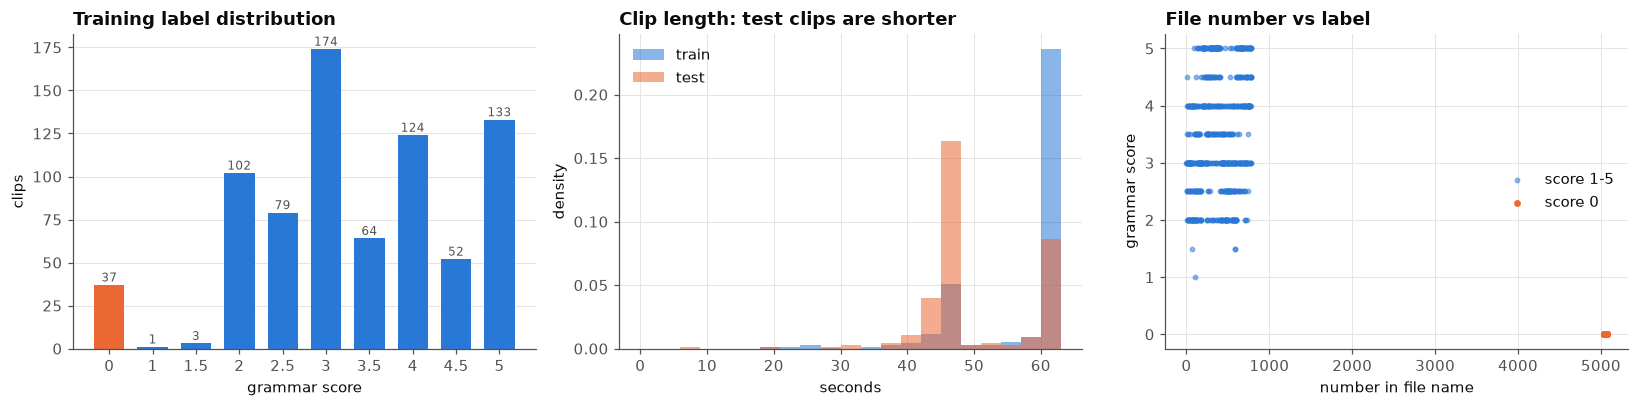

score-0 clips: 37, file numbers 5037-5073 (all consecutive: True)
median clip length  train 60.1s | test 45.1s
correlation(file number, label) in train: -0.55


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# (a) label distribution
counts = tr_meta["label"].value_counts().sort_index()
bars = axes[0].bar([f"{v:g}" for v in counts.index], counts.values, color=[ORANGE if v == 0 else BLUE for v in counts.index], width=0.7)
for b, c in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, c + 2, str(c), ha="center", fontsize=8, color=MUTED)
axes[0].set(title="Training label distribution", xlabel="grammar score", ylabel="clips")
axes[0].grid(axis="x", visible=False)

# (b) clip length: train vs test
edges = np.arange(0, 66, 3)
axes[1].hist(tr_meta["duration"], bins=edges, density=True, color=BLUE, alpha=0.55, label="train")
axes[1].hist(meta[meta.split == "test"]["duration"], bins=edges, density=True, color=ORANGE, alpha=0.55, label="test")
axes[1].set(title="Clip length: test clips are shorter", xlabel="seconds", ylabel="density"); axes[1].legend()

# (c) file number vs label: the score-0 clips are one consecutive batch
idx = tr_meta["filename"].str.extract(r"(\d+)")[0].astype(int)
zero = tr_meta["label"] == 0
axes[2].scatter(idx[~zero], tr_meta["label"][~zero], s=8, color=BLUE, alpha=0.5, label="score 1-5")
axes[2].scatter(idx[zero], tr_meta["label"][zero], s=12, color=ORANGE, label="score 0")
axes[2].set(title="File number vs label", xlabel="number in file name", ylabel="grammar score"); axes[2].legend(loc="center right")
plt.tight_layout(); savefig(fig, "data_overview"); plt.show()

print(f"score-0 clips: {zero.sum()}, file numbers {idx[zero].min()}-{idx[zero].max()} (all consecutive: {np.all(np.diff(np.sort(idx[zero])) == 1)})")
print(f"median clip length  train {tr_meta.duration.median():.1f}s | test {meta[meta.split=='test'].duration.median():.1f}s")
print(f"correlation(file number, label) in train: {np.corrcoef(idx, tr_meta['label'])[0, 1]:.2f}")

What the data shows:
* 37 clips are labelled 0 even though the rubric goes from 1 to 5. Their file numbers are consecutive (5037 to 5073), so they are a separate batch.
* Test clips are shorter than train clips, so only per-minute and per-word features are used, not totals like word count.
* Train and test reuse file names, so every clip is identified by split plus file name.
* File number correlates with the label in train. That is a leak, so file names are never used as a feature.

### 1.1 The test set is a different mix of recordings
Clip length splits the data into three recording batches: 45 s clips, 60 s clips and other lengths.

split,test %,train %
batch,,
45s,55.6,16.4
60s,26.9,71.8
other,17.6,11.8


label gap, 45 s clips vs others on the same prompt cluster: -0.40 score points


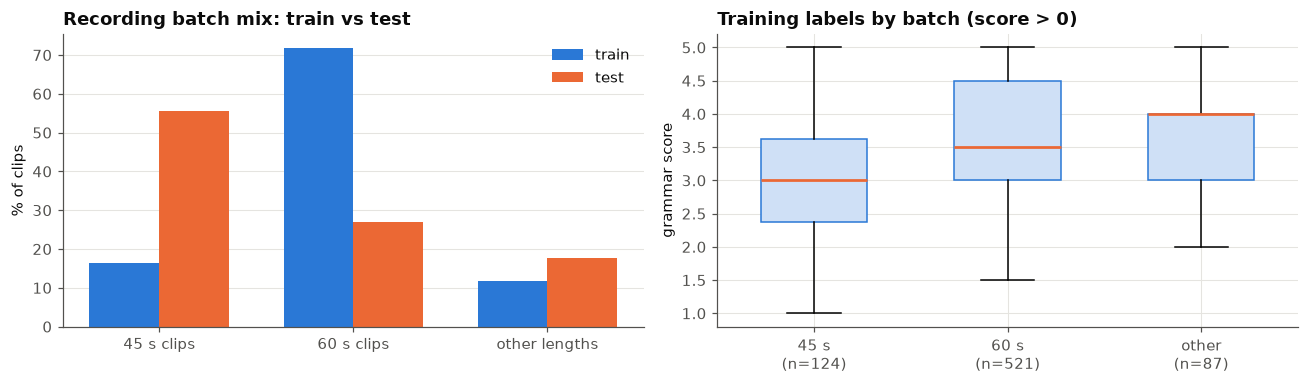

In [6]:
meta["batch"] = task_of(meta["duration"])
tr_meta = meta[meta.split == "train"]
mix = pd.crosstab(meta["batch"], meta["split"], normalize="columns").reindex(["45s", "60s", "other"])
display((100 * mix).round(1).rename(columns={"train": "train %", "test": "test %"}))

# Are 45 s clips scored differently on the SAME prompts? Prompts are approximated by clustering the transcripts.
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
texts_all = [load_transcripts()[k]["text"] for k in meta["key"]]
X_tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.3, sublinear_tf=True).fit_transform(texts_all)
meta["prompt_cluster"] = KMeans(20, n_init=5, random_state=0).fit(X_tfidf).labels_
nzt = meta[(meta.split == "train") & (meta.label > 0)].copy()
nzt["is45"] = (nzt["batch"] == "45s").astype(float)
dm = lambda s: s - nzt.groupby("prompt_cluster")[s.name].transform("mean")   # within-prompt deviations
gap = float((dm(nzt["label"]) * dm(nzt["is45"])).sum() / (dm(nzt["is45"]) ** 2).sum())
print(f"label gap, 45 s clips vs others on the same prompt cluster: {gap:+.2f} score points")
test_clusters = set(meta.loc[meta.split == "test", "prompt_cluster"])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
x = np.arange(3)
axes[0].bar(x - 0.18, 100 * mix["train"], 0.36, color=BLUE, label="train")
axes[0].bar(x + 0.18, 100 * mix["test"], 0.36, color=ORANGE, label="test")
axes[0].set_xticks(x, ["45 s clips", "60 s clips", "other lengths"])
axes[0].set(title="Recording batch mix: train vs test", ylabel="% of clips"); axes[0].legend(); axes[0].grid(axis="x", visible=False)
grp = [nzt.loc[nzt.batch == b, "label"] for b in ["45s", "60s", "other"]]
bp = axes[1].boxplot(grp, patch_artist=True, widths=0.55)
for box in bp["boxes"]:
    box.set(facecolor="#cfe0f6", edgecolor=BLUE)
for med in bp["medians"]:
    med.set(color=ORANGE, lw=1.8)
axes[1].set_xticks([1, 2, 3], [f"{b}\n(n={len(g)})" for b, g in zip(["45 s", "60 s", "other"], grp)])
axes[1].set(title="Training labels by batch (score > 0)", ylabel="grammar score")
plt.tight_layout(); savefig(fig, "batch_shift"); plt.show()

What this means:
* 56% of test clips are 45 s clips, compared to 17% of train. They are a separate recording batch and on the same prompts they get lower scores (gap printed above).
* So every base model gets two batch flags (is_45s, is_other) as extra inputs.
* None of the test clips look like the label-0 batch. The text models and the stacker are trained without those 37 clips, and predictions are clipped to [2, 5].

## 2. Preprocessing: speech to text with Whisper
Grammar can't be judged from raw audio, so each clip is first transcribed with Whisper large-v3-turbo. A short prompt with "umm" and false starts makes Whisper keep the speaker's mistakes instead of cleaning them up.

In [7]:
# ----- code that produced features/transcripts.jsonl (from src/02_transcribe.py) -------------------------------
PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. So, uh, I- I was going there."

def language_probs(model, audio):
    """Whisper language ID on the first 30 s -> (P(English), top language, P(top language))."""
    try:
        _, _, probs = model.detect_language(audio)
    except (AttributeError, TypeError):  # older faster-whisper: detection happens inside transcribe()
        _, info = model.transcribe(audio[: 30 * SR], language=None)
        probs = info.all_language_probs or []
    probs = dict(probs)
    top = max(probs, key=probs.get) if probs else "en"
    return float(probs.get("en", 0.0)), top, float(probs.get(top, 0.0))

def transcribe_one(model, audio, beam_size):
    en_prob, top_lang, top_prob = language_probs(model, audio)
    segments, info = model.transcribe(
        audio,
        language="en",                     # force English: accented English is often mis-detected
        beam_size=beam_size,
        word_timestamps=True,              # needed for pause / speech-rate features
        condition_on_previous_text=False,  # prevents repetition loops across segments
        initial_prompt=PROMPT,
        vad_filter=True,                   # skip silence -> no hallucinated text on silent clips
    )
    segs, words = [], []
    for s in segments:
        segs.append({
            "start": round(s.start, 2), "end": round(s.end, 2), "text": s.text.strip(),
            "avg_logprob": round(s.avg_logprob, 4), "no_speech_prob": round(s.no_speech_prob, 4),
            "compression_ratio": round(s.compression_ratio, 4),
        })
        words += [{"w": w.word.strip(), "s": round(w.start, 2), "e": round(w.end, 2), "p": round(w.probability, 4)}
                  for w in (s.words or [])]
    return {
        "text": " ".join(s["text"] for s in segs).strip(),
        "duration": round(len(audio) / SR, 2),
        "speech_duration": round(float(getattr(info, "duration_after_vad", 0.0) or 0.0), 2),
        "en_prob": round(en_prob, 4), "top_lang": top_lang, "top_lang_prob": round(top_prob, 4),
        "segments": segs, "words": words,
    }


def run_transcription(model_name="large-v3-turbo", beam=5):
    """Transcribe every clip that is not in transcripts.jsonl yet (resumable)."""
    expose_cuda_dlls()
    from faster_whisper import WhisperModel
    model = WhisperModel(model_name, device="cuda", compute_type="int8_float16")
    done = set(load_transcripts(missing_ok=True))
    todo = meta[~meta["key"].isin(done)]
    with open(TRANSCRIPTS, "a", encoding="utf-8") as fout:
        for row in tqdm(todo.itertuples(), total=len(todo), desc="transcribing"):
            rec = transcribe_one(model, load_audio(audio_path(row.split, row.filename)), beam)
            fout.write(json.dumps({"key": row.key, **rec}) + "\n")
            fout.flush()


if RUN_HEAVY:
    run_transcription()
transcripts = load_transcripts()
assert set(meta["key"]) == set(transcripts), "transcripts missing - set RUN_HEAVY = True"
print(f"{len(transcripts)} transcripts loaded")

985 transcripts loaded


## 3. Feature engineering
### 3.1 Audio features
WavLM-Large turns each clip into an embedding that captures how the person speaks (fluency, rhythm, pronunciation). A few simple prosody features are added too: pauses, loudness and pitch variation.

In [8]:
# ----- code that produced features/wavlm_layers.npy and acoustic.csv (from src/03_audio_features.py) ------------
import librosa
from transformers import WavLMModel

WAVLM_MODEL = "microsoft/wavlm-large"

CHUNK_S = 30          # WavLM is run on <=30 s chunks to bound GPU memory

HOP = 160             # 10 ms analysis hop for prosody

PAUSE_MIN_FRAMES = 30   # a silence >= 0.3 s counts as a pause

LONG_PAUSE_FRAMES = 100  # >= 1 s is a long pause

@torch.inference_mode()
def wavlm_layer_means(model, wav, device, use_amp=True):
    """Time-averaged hidden state of every WavLM layer -> (n_layers + 1, hidden)."""
    n_chunks = max(1, int(np.ceil(len(wav) / (CHUNK_S * SR))))
    sums, frames = None, 0
    for chunk in np.array_split(wav, n_chunks):
        x = (chunk - chunk.mean()) / (chunk.std() + 1e-7)  # WavLM-Large was trained on normalised audio
        x = torch.from_numpy(np.ascontiguousarray(x)).float().unsqueeze(0).to(device)
        amp = (torch.autocast("cuda", dtype=torch.float16) if use_amp and device.type == "cuda"
               else contextlib.nullcontext())
        with amp:
            hidden = model(x, output_hidden_states=True).hidden_states
        h = torch.stack(hidden, 0)[:, 0].float()  # (layers, T, hidden)
        sums = h.sum(1) if sums is None else sums + h.sum(1)
        frames += h.shape[1]
    out = (sums / frames).cpu().numpy()
    if use_amp and not np.isfinite(out).all():  # fp16 overflow -> redo this clip in fp32
        return wavlm_layer_means(model, wav, device, use_amp=False)
    return out

def run_lengths(mask):
    """Lengths of consecutive True runs in a boolean array."""
    padded = np.concatenate([[0], mask.astype(np.int8), [0]])
    d = np.diff(padded)
    return np.where(d == -1)[0] - np.where(d == 1)[0]

def acoustic_features(wav):
    rms = librosa.feature.rms(y=wav, frame_length=400, hop_length=HOP)[0]
    db = 20 * np.log10(rms + 1e-6)
    active = db > np.percentile(db, 95) - 35  # frames within 35 dB of the loud part = speech
    if active.sum() < 10:
        return {"ac_active_ratio": float(active.mean())}

    first, last = np.flatnonzero(active)[[0, -1]]
    inner_silence = ~active[first : last + 1]  # ignore leading / trailing silence
    pauses = run_lengths(inner_silence)
    pauses = pauses[pauses >= PAUSE_MIN_FRAMES]
    span_min = (last - first + 1) * HOP / SR / 60

    f0 = librosa.yin(wav, fmin=70, fmax=400, sr=SR, frame_length=1024, hop_length=HOP)
    n = min(len(f0), len(active))
    f0 = f0[:n][active[:n]]
    semitones = 12 * np.log2(f0 / np.median(f0))

    return {
        "ac_active_ratio": float(active.mean()),
        "ac_pauses_per_min": len(pauses) / span_min,
        "ac_long_pauses_per_min": float((pauses >= LONG_PAUSE_FRAMES).sum()) / span_min,
        "ac_mean_pause_s": float(pauses.mean() * HOP / SR) if len(pauses) else 0.0,
        "ac_loudness_mean": float(db[active].mean()),
        "ac_loudness_std": float(db[active].std()),
        "ac_f0_median": float(np.median(f0)),
        "ac_pitch_std_st": float(semitones.std()),
        "ac_pitch_range_st": float(np.percentile(semitones, 95) - np.percentile(semitones, 5)),
    }


def run_audio_features():
    device = get_device()
    model = WavLMModel.from_pretrained(WAVLM_MODEL).to(device).eval()
    emb = np.zeros((len(meta), model.config.num_hidden_layers + 1, model.config.hidden_size), dtype=np.float16)
    rows = []
    for i, row in enumerate(tqdm(meta.itertuples(), total=len(meta), desc="audio features")):
        wav = load_audio(audio_path(row.split, row.filename))
        emb[i] = wavlm_layer_means(model, wav, device)
        rows.append({"key": row.key, **acoustic_features(wav)})
    np.save(FEAT_DIR / "wavlm_layers.npy", emb)
    pd.DataFrame(rows).to_csv(FEAT_DIR / "acoustic.csv", index=False)


if RUN_HEAVY:
    run_audio_features()
wavlm = np.load(FEAT_DIR / "wavlm_layers.npy").astype(np.float32)
acoustic = pd.read_csv(FEAT_DIR / "acoustic.csv")
print("WavLM embeddings:", wavlm.shape, "(clips, layers, dims) | prosody features:", acoustic.shape[1] - 1)

WavLM embeddings: (985, 25, 1024) (clips, layers, dims) | prosody features: 9


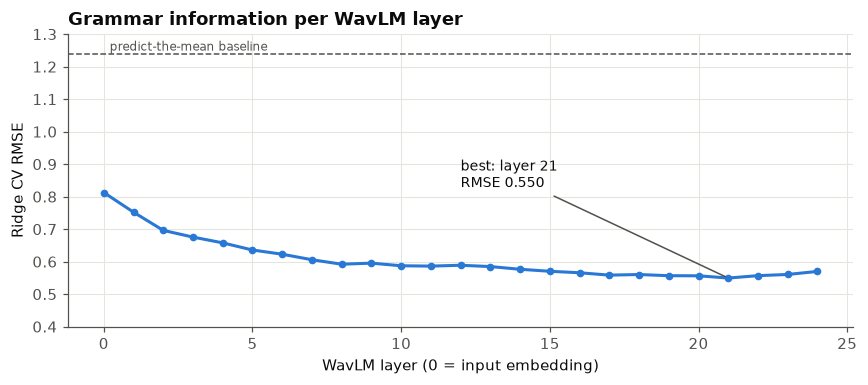

In [9]:
# Which WavLM layer predicts the grammar score best? Ridge regression on one layer at a time, 5-fold CV.
is_tr_all = (meta["split"] == "train").to_numpy()
y_all, folds_all = meta.loc[is_tr_all, "label"].to_numpy(), meta.loc[is_tr_all, "fold"].to_numpy()
cv_all = CV(y_all, folds_all)
layer_rmse_all = [rmse(cv_all.oof(ridge(), wavlm[is_tr_all, L]), y_all) for L in range(wavlm.shape[1])]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(len(layer_rmse_all)), layer_rmse_all, color=BLUE, lw=2, marker="o", ms=4)
best = int(np.argmin(layer_rmse_all))
ax.axhline(1.238, color=MUTED, ls="--", lw=1); ax.text(0.2, 1.24, "predict-the-mean baseline", color=MUTED, fontsize=8, va="bottom")
ax.annotate(f"best: layer {best}\nRMSE {layer_rmse_all[best]:.3f}", (best, layer_rmse_all[best]), xytext=(best - 9, layer_rmse_all[best] + 0.28),
            arrowprops=dict(arrowstyle="-", color=MUTED), color=INK, fontsize=9)
ax.set(title="Grammar information per WavLM layer", xlabel="WavLM layer (0 = input embedding)", ylabel="Ridge CV RMSE", ylim=(0.4, 1.3))
plt.tight_layout(); savefig(fig, "wavlm_layers"); plt.show()

Audio alone already gets an RMSE around 0.55, far below the 1.24 baseline. The best layers are around 19 to 22, so the models use the average of layers 20, 21 and 22.

### 3.2 Transcript features
* Speech statistics from the Whisper output (speaking rate, pauses, fillers, vocabulary).
* CoLA acceptability: a RoBERTa model trained to judge whether a sentence is grammatical.
* Grammar error correction with CoEdIT-large: how many word edits each sentence needs.
* Language model surprisal with Qwen2.5-0.5B.

In [10]:
# ----- speech statistics (live) - from src/04_text_features.py -----------------------------------------------
try:
    from wordfreq import zipf_frequency
except ImportError:  # optional dependency
    zipf_frequency = None

SUBORDINATORS = {"because", "although", "though", "which", "who", "whom", "whose", "when", "whenever", "while",
                 "whereas", "if", "unless", "since", "until", "after", "before", "that", "where", "whether"}

TIMING_KEYS = ["speak_span_ratio", "wpm_span", "artic_rate", "pauses_03_per_min", "pauses_1_per_min",
               "mean_pause", "max_pause", "word_prob_mean", "word_prob_p10", "low_prob_frac"]

def timing_stats(words, duration):
    """Speech-rate and pause features from Whisper word timestamps and word confidences."""
    if len(words) < 2:
        return dict.fromkeys(TIMING_KEYS, np.nan)
    start = np.array([w["s"] for w in words])
    end = np.array([w["e"] for w in words])
    prob = np.array([w["p"] for w in words])
    span = max(end[-1] - start[0], 1e-3)
    gaps = np.clip(start[1:] - end[:-1], 0, None)
    phonation = max(np.clip(end - start, 0, None).sum(), 1e-3)
    return {
        "speak_span_ratio": span / duration,
        "wpm_span": len(words) / span * 60,
        "artic_rate": len(words) / phonation * 60,
        "pauses_03_per_min": (gaps > 0.3).sum() / span * 60,
        "pauses_1_per_min": (gaps > 1.0).sum() / span * 60,
        "mean_pause": gaps[gaps > 0.3].mean() if (gaps > 0.3).any() else 0.0,
        "max_pause": gaps.max(),
        "word_prob_mean": prob.mean(),
        "word_prob_p10": np.percentile(prob, 10),
        "low_prob_frac": (prob < 0.5).mean(),
    }

def transcript_stats(rec):
    duration = max(rec["duration"], 1e-3)
    tokens = words_of(rec["text"])
    content = [t for t in tokens if t not in FILLERS]
    n = len(content)
    f = {
        "en_prob": rec["en_prob"],
        "top_lang_prob": rec["top_lang_prob"],
        "is_english": float(rec["top_lang"] == "en"),
        "vad_speech_ratio": rec["speech_duration"] / duration,
        "n_words": n,
        "wpm": n / duration * 60,
        "filler_rate": (len(tokens) - n) / max(len(tokens), 1),
        "repeat_rate": sum(a == b for a, b in zip(content, content[1:])) / max(n, 1),
        "root_ttr": len(set(content)) / np.sqrt(n) if n else np.nan,  # length-robust vocabulary richness
        "mean_word_len": np.mean([len(t) for t in content]) if n else np.nan,
        "long_word_frac": np.mean([len(t) >= 7 for t in content]) if n else np.nan,
        "subord_per_100w": 100 * sum(t in SUBORDINATORS for t in content) / n if n else np.nan,
    }
    sent_lens = [len(words_of(s)) for s in split_sentences(strip_fillers(rec["text"]), max_words=10_000)]
    f["n_sentences"] = len(sent_lens)
    f["sent_len_mean"] = np.mean(sent_lens) if sent_lens else np.nan
    f["sent_len_std"] = np.std(sent_lens) if sent_lens else np.nan
    f["sent_len_max"] = max(sent_lens) if sent_lens else np.nan
    if zipf_frequency is not None:
        zipf = np.array([zipf_frequency(t, "en") for t in content])
        f["zipf_mean"] = zipf.mean() if n else np.nan
        f["rare_word_frac"] = (zipf < 3.5).mean() if n else np.nan

    segs = rec["segments"]
    f["seg_logprob_mean"] = np.mean([s["avg_logprob"] for s in segs]) if segs else np.nan
    f["seg_logprob_min"] = np.min([s["avg_logprob"] for s in segs]) if segs else np.nan
    f["no_speech_mean"] = np.mean([s["no_speech_prob"] for s in segs]) if segs else np.nan
    f["compression_mean"] = np.mean([s["compression_ratio"] for s in segs]) if segs else np.nan
    f.update(timing_stats(rec["words"], duration))
    return f

def stage_stats(keys, recs):
    return pd.DataFrame([{"key": k, **transcript_stats(r)} for k, r in zip(keys, recs)])

keys = meta["key"].tolist()
recs = [transcripts[k] for k in keys]
texts = [r["text"] for r in recs]
stats = stage_stats(keys, recs)

# reproducibility check against the cached table from the original run
cached_stats = pd.read_csv(FEAT_DIR / "text_stats.csv")
print("live statistics identical to cached:", np.allclose(stats.drop(columns="key").to_numpy(float), cached_stats.drop(columns="key").to_numpy(float), equal_nan=True, atol=1e-6))
print(f"{stats.shape[1] - 1} speech-statistic features, e.g. {list(stats.columns[1:8])}")

live statistics identical to cached: True
32 speech-statistic features, e.g. ['en_prob', 'top_lang_prob', 'is_english', 'vad_speech_ratio', 'n_words', 'wpm', 'filler_rate']


In [11]:
# ----- neural grammar features (heavy; cached) - from src/04_text_features.py ---------------------------------
from transformers import AutoModelForCausalLM, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification, AutoTokenizer

COLA_MODEL = "textattack/roberta-base-CoLA"

GEC_MODEL = "grammarly/coedit-large"

GEC_PREFIX = "Fix grammatical errors in this sentence: "

LM_MODEL = "Qwen/Qwen2.5-0.5B"

@torch.inference_mode()
def acceptability(tok, model, sentences, device, batch_size=64):
    """P(label 1 = grammatically acceptable) for each sentence; length-sorted batches."""
    probs = np.zeros(len(sentences))
    order = np.argsort([len(s) for s in sentences])
    for i in tqdm(range(0, len(order), batch_size), desc="cola sentences"):
        idx = order[i : i + batch_size]
        enc = tok([sentences[j] for j in idx], padding=True, truncation=True, max_length=128,
                  return_tensors="pt").to(device)
        probs[idx] = model(**enc).logits.float().softmax(-1)[:, 1].cpu().numpy()
    return probs

@torch.inference_mode()
def mean_pooled_embeddings(tok, model, texts, device, batch_size=16):
    out = []
    for i in tqdm(range(0, len(texts), batch_size), desc="cola embeddings"):
        enc = tok(texts[i : i + batch_size], padding=True, truncation=True, max_length=512,
                  return_tensors="pt").to(device)
        h = model(**enc, output_hidden_states=True).hidden_states[-1]
        m = enc["attention_mask"].unsqueeze(-1).to(h.dtype)
        out.append(((h * m).sum(1) / m.sum(1).clamp(min=1)).float().cpu().numpy())
    return np.concatenate(out)

def stage_cola(keys, texts, device):
    tok = AutoTokenizer.from_pretrained(COLA_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(COLA_MODEL).to(device).eval()

    items = [(k, s) for k, t in zip(keys, texts) for s in split_sentences(strip_fillers(t))
             if len(s.split()) >= 3]
    df = pd.DataFrame(items, columns=["key", "sent"])
    df["p"] = acceptability(tok, model, df["sent"].tolist(), device) if len(df) else []
    df["nw"] = df["sent"].str.split().str.len()
    df["bad"] = (df["p"] < 0.5).astype(float)
    df["pw"] = df["p"] * df["nw"]
    agg = df.groupby("key").agg(cola_mean=("p", "mean"), cola_min=("p", "min"), cola_std=("p", "std"),
                                cola_bad_frac=("bad", "mean"), pw=("pw", "sum"), nw=("nw", "sum"))
    agg["cola_wmean"] = agg["pw"] / agg["nw"]
    feats = pd.DataFrame({"key": keys}).merge(agg.drop(columns=["pw", "nw"]), on="key", how="left")

    np.save(FEAT_DIR / "cola_emb.npy", mean_pooled_embeddings(tok, model, texts, device).astype(np.float32))
    return feats

@torch.inference_mode()
def correct(tok, model, sentences, device, batch_size=16):
    corrected = [""] * len(sentences)
    order = np.argsort([len(s) for s in sentences])
    for i in tqdm(range(0, len(order), batch_size), desc="grammar correction"):
        idx = order[i : i + batch_size]
        enc = tok([GEC_PREFIX + sentences[j] for j in idx], padding=True, truncation=True, max_length=192,
                  return_tensors="pt").to(device)
        out = model.generate(**enc, max_new_tokens=160, num_beams=1, do_sample=False)
        for j, text in zip(idx, tok.batch_decode(out, skip_special_tokens=True)):
            corrected[j] = text
    return corrected

def stage_gec(keys, texts, device):
    dtype = torch.bfloat16 if device.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
    tok = AutoTokenizer.from_pretrained(GEC_MODEL)
    model = AutoModelForSeq2SeqLM.from_pretrained(GEC_MODEL).to(device=device, dtype=dtype).eval()

    items = [(k, s) for k, t in zip(keys, texts) for s in split_sentences(strip_fillers(t))
             if len(words_of(s)) >= 2]
    df = pd.DataFrame(items, columns=["key", "sent"])
    df["corrected"] = correct(tok, model, df["sent"].tolist(), device) if len(df) else []
    df["nw"] = [len(words_of(s)) for s in df["sent"]]
    df["edits"] = [word_edit_distance(words_of(a), words_of(b)) for a, b in zip(df["sent"], df["corrected"])]
    df["changed"] = (df["edits"] > 0).astype(float)
    df.to_csv(FEAT_DIR / "gec_corrections.csv", index=False)  # kept for inspection in the notebook

    agg = df.groupby("key").agg(edits=("edits", "sum"), nw=("nw", "sum"), gec_changed_frac=("changed", "mean"),
                                gec_max_edits=("edits", "max"), gec_mean_edits=("edits", "mean"))
    agg["gec_edits_per_100w"] = 100 * agg["edits"] / agg["nw"].clip(lower=1)
    return pd.DataFrame({"key": keys}).merge(agg.drop(columns=["edits", "nw"]), on="key", how="left")

@torch.inference_mode()
def stage_lm(keys, texts, device):
    dtype = torch.bfloat16 if device.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float32
    tok = AutoTokenizer.from_pretrained(LM_MODEL)
    model = AutoModelForCausalLM.from_pretrained(LM_MODEL).to(device=device, dtype=dtype).eval()

    rows = []
    for k, t in tqdm(list(zip(keys, texts)), desc="lm surprisal"):
        ids = tok(strip_fillers(t), return_tensors="pt", truncation=True, max_length=1024).input_ids.to(device)
        if ids.shape[1] < 4:
            rows.append({"key": k})
            continue
        logits = model(ids).logits[0, :-1].float()
        nll = F.cross_entropy(logits, ids[0, 1:], reduction="none").cpu().numpy()
        rows.append({"key": k, "lm_nll_mean": nll.mean(), "lm_nll_median": np.median(nll),
                     "lm_nll_p90": np.percentile(nll, 90), "lm_surprise_frac": (nll > 6).mean()})
    return pd.DataFrame(rows)


def build_text_features():
    """Recompute the three neural stages and merge with the speech statistics."""
    device = get_device()
    for name, fn in [("cola", lambda: stage_cola(keys, texts, device)), ("gec", lambda: stage_gec(keys, texts, device)),
                     ("lm", lambda: stage_lm(keys, texts, device))]:
        fn().to_csv(FEAT_DIR / f"text_{name}.csv", index=False)
    feats = stats
    for name in ("cola", "gec", "lm"):
        feats = feats.merge(pd.read_csv(FEAT_DIR / f"text_{name}.csv"), on="key", how="left")
    feats.to_csv(FEAT_DIR / "text_features.csv", index=False)


if RUN_HEAVY:
    build_text_features()
text_features = pd.read_csv(FEAT_DIR / "text_features.csv")
cola_emb = np.load(FEAT_DIR / "cola_emb.npy")
print("text features:", text_features.shape[1] - 1, "| CoLA embedding:", cola_emb.shape)

text features: 45 | CoLA embedding: (985, 768)


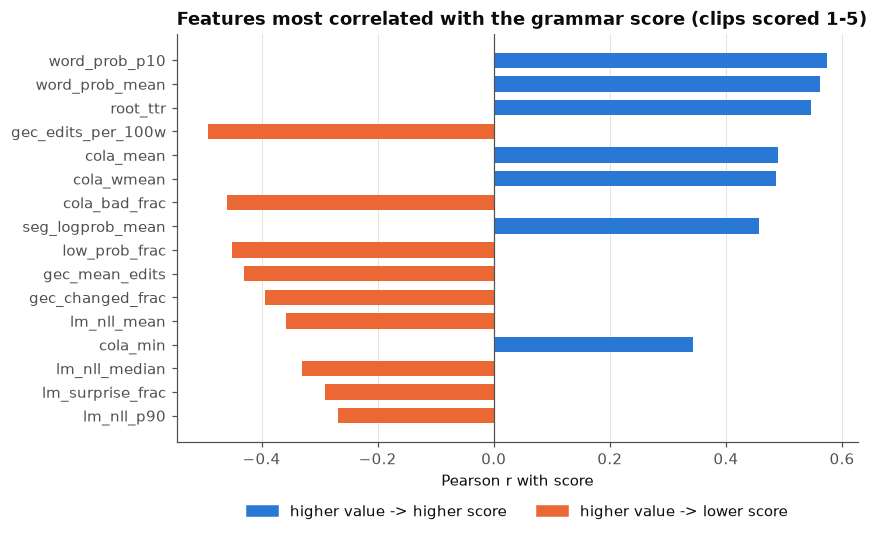

In [12]:
# How strongly does each hand-crafted feature relate to the score? (Pearson r on the training clips)
feat_df = meta[["key", "label"]].merge(acoustic, on="key").merge(text_features, on="key")
feat_df = feat_df[feat_df.label > 0]          # exclude the score-0 batch so the chart shows real grammar/fluency signal
corr = feat_df.drop(columns=["key", "label"] + LENGTH_DEPENDENT).corrwith(feat_df["label"]).dropna()   # only features the models use
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(16)[::-1]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.65)
ax.axvline(0, color=MUTED, lw=0.8)
ax.set(title="Features most correlated with the grammar score (clips scored 1-5)", xlabel="Pearson r with score")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="higher value -> higher score"), Patch(color=ORANGE, label="higher value -> lower score")], loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.tight_layout(); savefig(fig, "feature_correlation"); plt.show()

Clips that need fewer corrections, have more grammatical sentences and a wider vocabulary get higher scores. No single feature is enough, so the models combine them.

### 3.3 Grammar error types (new in v2)
Each edit made by the correction model is sorted into a type: article, preposition, auxiliary, inflection, pronoun, conjunction, other word, or a disfluency repair (false start or repeat). The counts per 100 words are added to the tabular features. This runs on CPU in seconds.

In [13]:
# ----- code that produced features/v2/error_types.csv (from src_v2/03_error_types.py) ---------------------------
from difflib import SequenceMatcher

TOK = re.compile(r"[a-z0-9]+(?:'[a-z]+)?-?")  # keeps the trailing hyphen of false starts ("the-")
ARTICLES = {"a", "an", "the"}
PREPS = {"in", "on", "at", "to", "for", "of", "with", "from", "by", "about", "into", "onto", "over", "under", "through",
         "during", "since", "until", "towards", "toward", "around", "between", "among", "across", "after", "before",
         "upon", "within", "without", "like"}
AUX = {"is", "are", "was", "were", "be", "been", "being", "am", "have", "has", "had", "do", "does", "did", "will",
       "would", "can", "could", "shall", "should", "may", "might", "must"}
PRON = {"i", "you", "he", "she", "it", "we", "they", "me", "him", "her", "us", "them", "my", "your", "his", "its",
        "our", "their", "this", "that", "these", "those", "there", "which", "who", "what"}
CONJ = {"and", "but", "or", "so", "because", "although", "though", "if", "when", "while", "that"}
TYPES = ["disfl", "article", "prep", "aux", "infl", "pron", "conj", "content_ins", "content_del", "content_rep"]
GRAMMAR = TYPES[1:]


def same_lemma(a, b):
    """Different inflections of the same word (play / plays / played / playing)."""
    if a == b:
        return False
    k = 0
    while k < min(len(a), len(b)) and a[k] == b[k]:
        k += 1
    return k >= max(3, min(len(a), len(b)) - 2)


def word_class(w, fallback):
    for name, vocab in (("article", ARTICLES), ("prep", PREPS), ("aux", AUX), ("pron", PRON), ("conj", CONJ)):
        if w in vocab:
            return name
    return fallback


def classify(src, tgt):
    raw = TOK.findall(src.lower())
    s = [w.rstrip("-") for w in raw]
    t = [w.rstrip("-") for w in TOK.findall(tgt.lower())]
    c = dict.fromkeys(TYPES + ["n_ops", "n_tok_changed"], 0)
    for op, i1, i2, j1, j2 in SequenceMatcher(a=s, b=t, autojunk=False).get_opcodes():
        if op == "equal":
            continue
        c["n_ops"] += 1
        c["n_tok_changed"] += max(i2 - i1, j2 - j1)
        if op == "delete":
            for k in range(i1, i2):
                w = s[k]
                nxt = s[i2] if i2 < len(s) else ""
                prv = s[i1 - 1] if i1 > 0 else ""
                repeated = w in (nxt, prv) or (k + 1 < i2 and s[k + 1] == w)
                c["disfl" if raw[k].endswith("-") or repeated else word_class(w, "content_del")] += 1
        elif op == "insert":
            for w in t[j1:j2]:
                c[word_class(w, "content_ins")] += 1
        else:  # replace
            for a, b in zip(s[i1:i2], t[j1:j2]):
                if a in ARTICLES and b in ARTICLES:
                    c["article"] += 1
                elif a in PREPS and b in PREPS:
                    c["prep"] += 1
                elif a in AUX or b in AUX:
                    c["aux"] += 1
                elif same_lemma(a, b):
                    c["infl"] += 1
                elif a in PRON or b in PRON:
                    c["pron"] += 1
                else:
                    c["content_rep"] += 1
            c["content_rep"] += abs((i2 - i1) - (j2 - j1))
    return c


def build_error_types():
    g = pd.read_csv(FEAT_DIR / "gec_corrections.csv")
    e = pd.concat([g[["key", "nw"]].reset_index(drop=True),
                   pd.DataFrame([classify(a, str(b)) for a, b in zip(g["sent"], g["corrected"])])], axis=1)
    agg = e.groupby("key").sum(numeric_only=True)
    nw = agg.pop("nw").clip(lower=1)
    feats = agg.div(nw, axis=0) * 100
    feats.columns = [f"et_{c}_p100" for c in feats.columns]
    feats["et_grammar_p100"] = agg[GRAMMAR].sum(axis=1) / nw * 100
    feats["et_core_p100"] = agg[["article", "prep", "aux", "infl"]].sum(axis=1) / nw * 100
    feats = feats.reindex(meta["key"])
    feats.index.name = "key"
    return feats.reset_index()


error_types = build_error_types()
cached_et = pd.read_csv(V2_FEAT / "error_types.csv")
print("live error types identical to cached:", np.allclose(error_types.drop(columns="key").to_numpy(float),
      cached_et.drop(columns="key").to_numpy(float), equal_nan=True))

live error types identical to cached: True


### 3.4 Whisper encoder and Qwen2.5-1.5B embeddings (new in v2)
* Whisper large-v3-turbo encoder: a second audio embedding next to WavLM. Whisper was trained to transcribe speech, so it picks up how clearly the words are formed. Layers 27 to 29 are used.
* Qwen2.5-1.5B: a language model reads the transcript (fillers removed) and its hidden states are averaged into an embedding. Layers 17 to 19 are used. This worked better than the 0.5B model on prompts not seen in training.

Both need a GPU (about 8 and 3 minutes) so the results are cached.

In [14]:
# ----- code that produced features/v2/whisper_encoder_layers.npy and qwen_layers.npy (src_v2/01 and 02) -----------
from transformers import AutoModel, WhisperFeatureExtractor, WhisperModel

WHISPER_MODEL, QWEN_MODEL = "openai/whisper-large-v3-turbo", "Qwen/Qwen2.5-1.5B"
WIN, FRAMES_PER_S = 30 * SR, 50          # Whisper sees 30 s windows; its encoder outputs 50 frames per second


@torch.inference_mode()
def run_whisper_encoder():
    fe = WhisperFeatureExtractor.from_pretrained(WHISPER_MODEL)
    enc = WhisperModel.from_pretrained(WHISPER_MODEL, dtype=torch.float16).get_encoder().cuda().eval()
    means = np.zeros((len(meta), enc.config.encoder_layers + 1, enc.config.d_model), np.float16)
    for i, row in enumerate(tqdm(meta.itertuples(), total=len(meta), desc="whisper encoder")):
        wav = load_audio(audio_path(row.split, row.filename))
        total, n = None, 0
        for start in range(0, len(wav), WIN):
            chunk = wav[start:start + WIN]
            if start > 0 and len(chunk) < SR // 2:          # ignore a sub-0.5 s tail
                continue
            feats = fe(chunk, sampling_rate=SR, return_tensors="pt").input_features.cuda().half()
            hidden = enc(feats, output_hidden_states=True).hidden_states
            valid = min(1500, int(np.ceil(len(chunk) / SR * FRAMES_PER_S)))   # skip Whisper's padding frames
            h = torch.stack(hidden, 0)[:, 0, :valid].float()
            total = h.sum(1) if total is None else total + h.sum(1)
            n += valid
        means[i] = (total / n).cpu().numpy()
    np.save(V2_FEAT / "whisper_encoder_layers.npy", means)


@torch.inference_mode()
def run_qwen_embeddings(max_len=512):
    texts_nf = [strip_fillers(transcripts[k]["text"]) for k in meta["key"]]
    tok = AutoTokenizer.from_pretrained(QWEN_MODEL)
    model = AutoModel.from_pretrained(QWEN_MODEL, dtype=torch.float16).cuda().eval()
    out = np.zeros((len(texts_nf), model.config.num_hidden_layers + 1, model.config.hidden_size), np.float16)
    for i, t in enumerate(tqdm(texts_nf, desc="qwen embeddings")):
        ids = tok(t or ".", return_tensors="pt", truncation=True, max_length=max_len).input_ids.cuda()
        hidden = model(ids, output_hidden_states=True).hidden_states
        out[i] = torch.stack(hidden, 0)[:, 0].float().mean(1).cpu().numpy()
    np.save(V2_FEAT / "qwen_layers.npy", out)


if RUN_HEAVY:
    run_whisper_encoder()
    run_qwen_embeddings()
whisper_layers = np.load(V2_FEAT / "whisper_encoder_layers.npy")
qwen_layers = np.load(V2_FEAT / "qwen_layers.npy")
print("Whisper encoder:", whisper_layers.shape, "| Qwen2.5-1.5B:", qwen_layers.shape, "(clips, layers, dims)")

Whisper encoder: (985, 33, 1280) | Qwen2.5-1.5B: (985, 29, 1536) (clips, layers, dims)


### 3.5 DeBERTa fine-tuned on the transcript


In [15]:
# ----- code that produced features/v2/deberta_nz.csv (from src_v2/04_finetune_deberta.py) -----------------------
import math, random
from transformers import get_cosine_schedule_with_warmup

DEBERTA_MODEL, MAX_LEN = "microsoft/deberta-v3-base", 384


class TextRegressor(nn.Module):
    def __init__(self, init_bias):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(DEBERTA_MODEL, hidden_dropout_prob=0.0, attention_probs_dropout_prob=0.0)
        self.backbone.float()                                   # AMP needs fp32 master weights
        self.backbone.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        for p in self.backbone.embeddings.parameters():
            p.requires_grad = False
        self.head = nn.Linear(self.backbone.config.hidden_size, 1)
        nn.init.normal_(self.head.weight, std=0.02)
        nn.init.constant_(self.head.bias, init_bias)            # start at the mean label -> stable first steps

    def forward(self, ids, mask):
        h = self.backbone(input_ids=ids, attention_mask=mask).last_hidden_state
        m = mask.unsqueeze(-1).to(h.dtype)
        return self.head((h * m).sum(1) / m.sum(1).clamp(min=1.0)).squeeze(-1)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def deberta_nz_finetune(seeds=(42, 43, 44), epochs=5, batch_size=8, lr=3e-5):
    dev = torch.device("cuda")
    tok = AutoTokenizer.from_pretrained(DEBERTA_MODEL)
    enc = tok([transcripts[k]["text"] for k in meta["key"]], truncation=True, max_length=MAX_LEN)
    y = meta["label"].to_numpy()
    folds = meta["fold"].to_numpy()
    train_idx, test_idx = np.where(meta["split"] == "train")[0], np.where(meta["split"] == "test")[0]

    def make_batch(idx):
        b = tok.pad({"input_ids": [enc["input_ids"][j] for j in idx],
                     "attention_mask": [enc["attention_mask"][j] for j in idx]}, return_tensors="pt")
        return b["input_ids"].to(dev), b["attention_mask"].to(dev)

    @torch.inference_mode()
    def predict(model, idx):
        model.eval()
        order = sorted(idx, key=lambda j: len(enc["input_ids"][j]))
        preds = {}
        for i in range(0, len(order), 32):
            chunk = order[i:i + 32]
            ids, mask = make_batch(chunk)
            with torch.autocast("cuda", dtype=torch.float16):
                preds.update(zip(chunk, model(ids, mask).float().cpu().numpy()))
        return np.array([preds[j] for j in idx])

    oof, test_pred = np.zeros(len(meta)), np.zeros(len(test_idx))
    for seed in seeds:
        for fold in range(N_FOLDS):
            seed_everything(seed + fold)
            fit_idx = train_idx[(folds[train_idx] != fold) & (y[train_idx] > 0)]   # label-0 clips never trained on
            val_idx = train_idx[folds[train_idx] == fold]
            model = TextRegressor(float(y[fit_idx].mean())).to(dev)
            opt = torch.optim.AdamW([{"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": lr},
                                     {"params": model.head.parameters(), "lr": 1e-3}], weight_decay=0.01)
            steps = epochs * math.ceil(len(fit_idx) / batch_size)
            sched = get_cosine_schedule_with_warmup(opt, int(0.1 * steps), steps)
            scaler = torch.amp.GradScaler("cuda")
            rng = np.random.default_rng(seed + fold)
            for _ in range(epochs):                              # fixed epochs, no best-epoch picking -> honest OOF
                model.train()
                perm = rng.permutation(fit_idx)
                for i in range(0, len(perm), batch_size):
                    b = perm[i:i + batch_size]
                    ids, mask = make_batch(b)
                    with torch.autocast("cuda", dtype=torch.float16):
                        pred = model(ids, mask)
                    loss = F.mse_loss(pred.float(), torch.tensor(y[b], dtype=torch.float32, device=dev))
                    opt.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(opt); scaler.update(); sched.step()
            oof[val_idx] += predict(model, val_idx) / len(seeds)
            test_pred += predict(model, test_idx) / (N_FOLDS * len(seeds))
            del model, opt
            torch.cuda.empty_cache()
    out = pd.DataFrame({"key": meta["key"], "deberta_nz": oof})
    out.loc[test_idx, "deberta_nz"] = test_pred
    out.to_csv(V2_FEAT / "deberta_nz.csv", index=False)


if RUN_HEAVY:
    deberta_nz_finetune()
deb_nz = pd.read_csv(V2_FEAT / "deberta_nz.csv").set_index("key").reindex(meta["key"])["deberta_nz"].to_numpy()
pos = ((meta["split"] == "train") & (meta["label"] > 0)).to_numpy()
print(f"DeBERTa out-of-fold RMSE on clips with score > 0: {rmse(deb_nz[pos], meta.label[pos]):.4f}")
if (FEAT_DIR / "deberta_preds.csv").exists():   # v1 DeBERTa, trained with the label-0 clips (src/05)
    deb_v1 = pd.read_csv(FEAT_DIR / "deberta_preds.csv").set_index("key").reindex(meta["key"])["deberta"].to_numpy()
    print(f"same model trained with the label-0 clips (v1): {rmse(deb_v1[pos], meta.label[pos]):.4f}")

W1002 15:33:09.881000 24300 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


DeBERTa out-of-fold RMSE on clips with score > 0: 0.5799
same model trained with the label-0 clips (v1): 0.6364


## 4. Model and ensemble

Eight base models, all on the same 5 folds. Every model also gets the two batch flags as input.

| Model | Input | Trained on |
|---|---|---|
| wavlm_svr | WavLM embedding (layers 20-22) | all clips |
| wavlm_ridge | same | score > 0 |
| whisper_ridge | Whisper encoder embedding (layers 27-29) | score > 0 |
| qwen_ridge | Qwen2.5-1.5B transcript embedding (layers 17-19) | score > 0 |
| cola_svr | CoLA RoBERTa transcript embedding | score > 0 |
| tab_ridge | hand-made audio and text features + error types | score > 0 |
| tab_lgbm | same | score > 0 |
| deberta_nz | transcript, fine-tuned (3.5) | score > 0 |

A non-negative linear regression (the stacker) combines their out-of-fold predictions, and the result is clipped to [2, 5]. The stacker is also refitted inside each fold, so the ensemble CV score is honest.

In [16]:
def run_v2():
    is_te = (meta["split"] == "test").to_numpy()
    is_tr = ~is_te
    tr, te = meta[is_tr].reset_index(drop=True), meta[is_te].reset_index(drop=True)
    y, folds = tr["label"].to_numpy(), tr["fold"].to_numpy()
    nz = y > 0
    w_test = test_mix_weights(meta, is_tr, y)

    def aligned(path):
        return pd.read_csv(path).set_index("key").reindex(meta["key"])

    tab = pd.concat([aligned(FEAT_DIR / "acoustic.csv"), aligned(FEAT_DIR / "text_features.csv")], axis=1)
    tab = tab.drop(columns=[c for c in LENGTH_DEPENDENT if c in tab.columns])
    X_tab_v1 = tab.replace([np.inf, -np.inf], np.nan).to_numpy(np.float64)
    tab = pd.concat([tab, aligned(V2_FEAT / "error_types.csv")], axis=1).replace([np.inf, -np.inf], np.nan)
    X_tab = tab.to_numpy(np.float64)
    X_wav = wavlm[:, [20, 21, 22]].mean(1)
    X_qwen = qwen_layers[:, [17, 18, 19]].astype(np.float32).mean(1)
    X_whisper = whisper_layers[:, [27, 28, 29]].astype(np.float32).mean(1)
    D = task_flags(meta)
    flagged = lambda X: np.hstack([X, D])

    # name -> (model, features, train on score > 0 only?)
    specs = {
        "wavlm_svr": (svr(3, 0.05), flagged(X_wav), False),
        "wavlm_ridge": (ridge(), flagged(X_wav), True),
        "cola_svr": (svr(3, 0.1), flagged(cola_emb), True),
        "tab_ridge": (ridge(), flagged(X_tab), True),
        "tab_lgbm": (lgbm(), flagged(X_tab), True),
        "qwen_ridge": (ridge(), flagged(X_qwen), True),
        "whisper_ridge": (ridge(), flagged(X_whisper), True),
    }
    oof, test, insample = {}, {}, {}
    for name, (model, X, nz_only) in specs.items():
        fit = nz if nz_only else np.ones(len(y), bool)
        oof[name], test[name] = run_cv(model, X[is_tr], y, folds, X[is_te], fit_mask=fit)
        insample[name] = clone(model).fit(X[is_tr][fit], y[fit]).predict(X[is_tr])   # for the training RMSE
    oof["deberta_nz"], test["deberta_nz"] = deb_nz[is_tr], deb_nz[is_te]
    insample["deberta_nz"] = deb_nz[is_tr]          # fold models were not kept -> its OOF prediction is used here

    names = list(oof)
    P_oof, P_test, P_ins = (np.column_stack([d[n] for n in names]) for d in (oof, test, insample))
    ens_oof = stack_oof(P_oof, y, folds, nz)
    stacker = LinearRegression(positive=True).fit(P_oof[nz], y[nz])
    final_test = np.clip(stacker.predict(P_test), *CLIP)
    ens_ins = np.clip(stacker.predict(P_ins), *CLIP)
    return dict(tr=tr, te=te, y=y, folds=folds, nz=nz, w_test=w_test, names=names, oof=oof, P_oof=P_oof,
                ens_oof=ens_oof, ens_ins=ens_ins, stacker=stacker, final_test=final_test, specs=specs,
                X_wav=X_wav, X_tab_v1=X_tab_v1, task=task_of(tr["duration"]))


t0 = time.time()
v2 = run_v2()
y, nz, w = v2["y"], v2["nz"], v2["w_test"]
print(f"ensemble trained in {time.time() - t0:.0f}s | train clips {len(y)} ({nz.sum()} with score > 0) | test clips {len(v2['te'])}")
rows = [{"model": n, "CV RMSE (score>0)": rmse(v2["oof"][n][nz], y[nz]), "CV RMSE test-weighted": wrmse(v2["oof"][n], y, w),
         "CV Pearson": pearson(v2["oof"][n][nz], y[nz]), "stacker weight": c} for n, c in zip(v2["names"], v2["stacker"].coef_)]
e = v2["ens_oof"]
rows.append({"model": "ENSEMBLE", "CV RMSE (score>0)": rmse(e[nz], y[nz]), "CV RMSE test-weighted": wrmse(e, y, w),
             "CV Pearson": pearson(e[nz], y[nz]), "stacker weight": np.nan})
model_table = pd.DataFrame(rows).set_index("model")
display(model_table.round(4).fillna(""))
print(f"stacker intercept {v2['stacker'].intercept_:+.3f}")

ensemble trained in 7s | train clips 769 (732 with score > 0) | test clips 216


,CV RMSE (score>0),CV RMSE test-weighted,CV Pearson,stacker weight
model,,,,
wavlm_svr,0.5215,0.5777,0.8577,0.5657
wavlm_ridge,0.5550,0.5920,0.8369,0.0
cola_svr,0.6466,0.6371,0.7702,0.037
tab_ridge,0.6515,0.6574,0.7662,0.0773
tab_lgbm,0.6257,0.6509,0.7868,0.0
qwen_ridge,0.6065,0.6060,0.8016,0.1379
whisper_ridge,0.5485,0.5788,0.8410,0.1134
deberta_nz,0.5799,0.5727,0.8211,0.2045
ENSEMBLE,0.4817,0.5110,0.8801,


stacker intercept -0.474


In [17]:
ins = v2["ens_ins"]
metrics_table = pd.DataFrame({
    "RMSE": [rmse(np.full(nz.sum(), y[nz].mean()), y[nz]), rmse(ins[nz], y[nz]), rmse(e[nz], y[nz]), wrmse(e, y, w)],
    "Pearson r": [np.nan, pearson(ins[nz], y[nz]), pearson(e[nz], y[nz]), np.nan],
}, index=["baseline: always predict the mean", "TRAINING data (models fitted on all training clips, predicting them)",
          "5-fold cross-validation (unseen clips)", "5-fold cross-validation, test-weighted"])
display(metrics_table.round(4))
print(f"TRAINING RMSE = {rmse(ins[nz], y[nz]):.4f}   (all 769 rows incl. the label-0 batch: {rmse(ins, y):.4f})")
print(f"CV RMSE       = {rmse(e[nz], y[nz]):.4f}   (test-weighted {wrmse(e, y, w):.4f})   CV Pearson = {pearson(e[nz], y[nz]):.4f}")
print(f"CV MAE = {np.mean(np.abs(e[nz] - y[nz])):.3f} score points")

rep = json.loads((V2_OUT / "cv_report_v2.json").read_text())
print("matches the numbers stored by the script run (src_v2/05):",
      abs(rep["v2_cv"]["rmse_label_gt0"] - rmse(e[nz], y[nz])) < 1e-6 and abs(rep["v2_cv"]["rmse_test_weighted"] - wrmse(e, y, w)) < 1e-6)

,RMSE,Pearson r
baseline: always predict the mean,1.0137,NaN
"TRAINING data (models fitted on all training clips, predicting them)",0.2251,0.9754
5-fold cross-validation (unseen clips),0.4817,0.8801
"5-fold cross-validation, test-weighted",0.5110,NaN


TRAINING RMSE = 0.2251   (all 769 rows incl. the label-0 batch: 0.4906)
CV RMSE       = 0.4817   (test-weighted 0.5110)   CV Pearson = 0.8801
CV MAE = 0.363 score points
matches the numbers stored by the script run (src_v2/05): True


RMSE values are on the clips scored 1 to 5 (the test set has no label-0 clips).

The training RMSE is low because the models are predicting clips they were trained on. For DeBERTa I used its out-of-fold predictions here since the fold models were not saved, so the real training RMSE is a bit lower still. The cross-validated RMSE is the honest number for new clips.

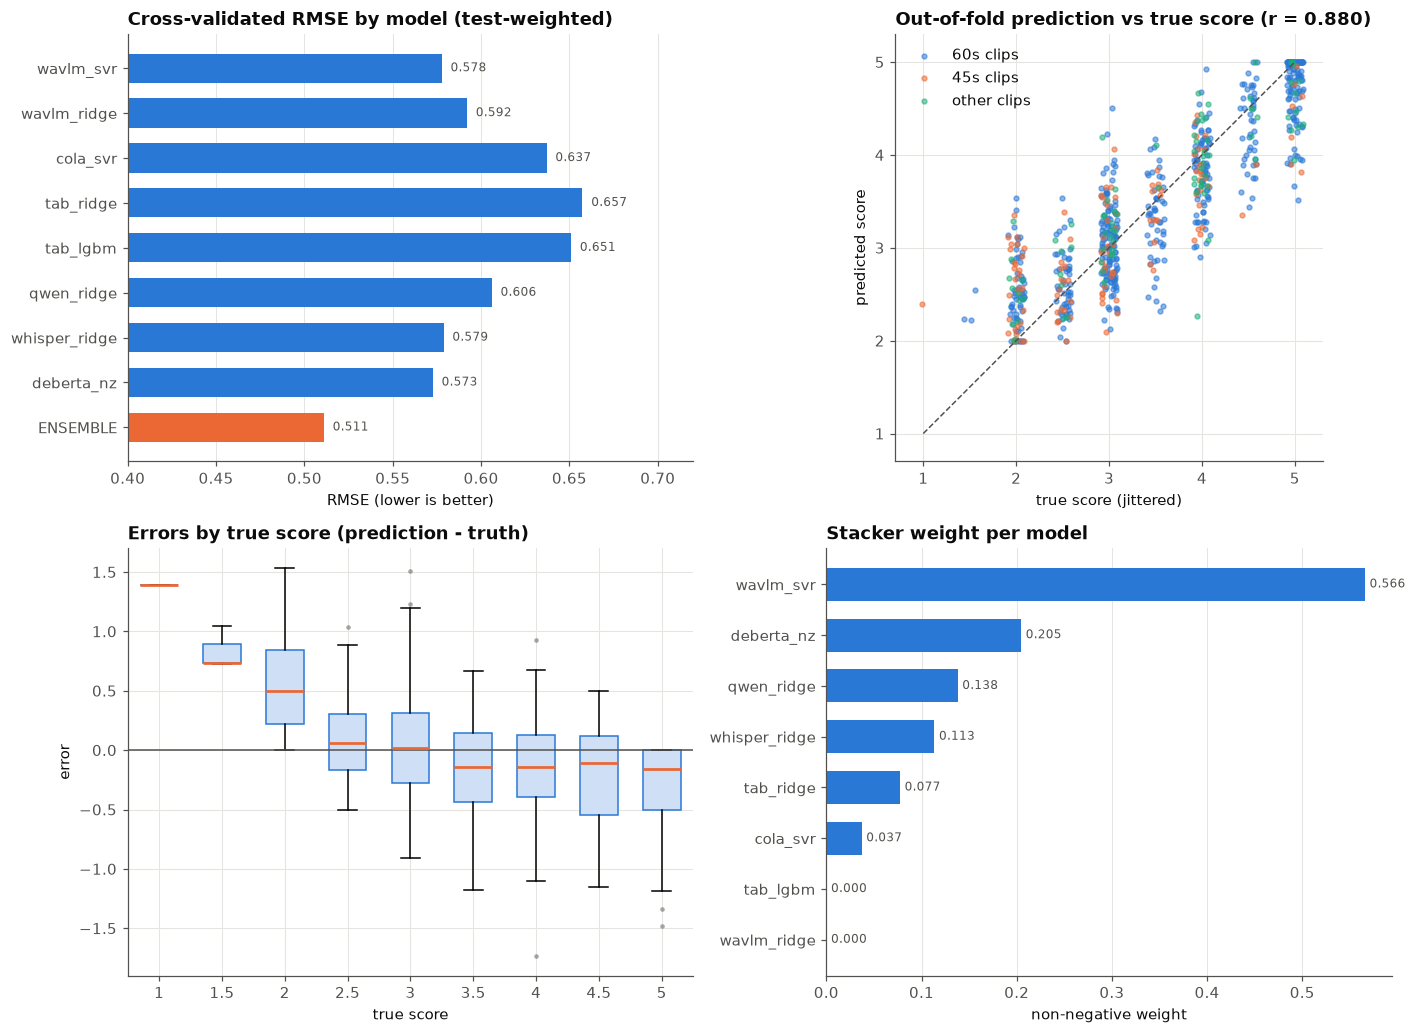

,clips,CV RMSE,mean error (bias)
45s,124.0,0.541,0.052
60s,521.0,0.467,-0.030
other,87.0,0.476,0.057


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))

# (a) model comparison (test-weighted CV RMSE)
ax = axes[0, 0]
t = model_table["CV RMSE test-weighted"]
ax.barh(t.index, t.values, color=[ORANGE if n == "ENSEMBLE" else BLUE for n in t.index], height=0.65)
for i, v in enumerate(t.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(title="Cross-validated RMSE by model (test-weighted)", xlabel="RMSE (lower is better)", xlim=(0.4, 0.72))

# (b) predicted vs actual
ax = axes[0, 1]
jit = np.random.default_rng(0).uniform(-0.09, 0.09, nz.sum())
for b, col in [("60s", BLUE), ("45s", ORANGE), ("other", AQUA)]:
    m = v2["task"][nz] == b
    ax.scatter(y[nz][m] + jit[m], e[nz][m], s=10, color=col, alpha=0.55, label=f"{b} clips")
ax.plot([1, 5], [1, 5], color=MUTED, lw=1, ls="--")
ax.set(title=f"Out-of-fold prediction vs true score (r = {pearson(e[nz], y[nz]):.3f})", xlabel="true score (jittered)",
       ylabel="predicted score", xlim=(0.7, 5.3), ylim=(0.7, 5.3)); ax.set_aspect("equal"); ax.legend(loc="upper left")

# (c) residuals by true score
ax = axes[1, 0]
levels = np.sort(np.unique(y[nz]))
bp = ax.boxplot([e[nz][y[nz] == v] - v for v in levels], patch_artist=True, widths=0.6,
                flierprops=dict(marker="o", ms=3, mfc=MUTED, mec="none", alpha=0.5))
for box in bp["boxes"]:
    box.set(facecolor="#cfe0f6", edgecolor=BLUE)
for med in bp["medians"]:
    med.set(color=ORANGE, lw=1.8)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(range(1, len(levels) + 1), [f"{v:g}" for v in levels])
ax.set(title="Errors by true score (prediction - truth)", xlabel="true score", ylabel="error")

# (d) stacker weights
ax = axes[1, 1]
wts = pd.Series(v2["stacker"].coef_, index=v2["names"]).sort_values()
ax.barh(wts.index, wts.values, color=BLUE, height=0.65); ax.grid(axis="y", visible=False)
for i, v in enumerate(wts.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.set(title="Stacker weight per model", xlabel="non-negative weight")
plt.tight_layout(); savefig(fig, "ensemble_results"); plt.show()

by = pd.DataFrame({b: {"clips": int((nz & (v2["task"] == b)).sum()),
                       "CV RMSE": rmse(e[nz & (v2["task"] == b)], y[nz & (v2["task"] == b)]),
                       "mean error (bias)": float((e - y)[nz & (v2["task"] == b)].mean())} for b in ["45s", "60s", "other"]}).T
display(by.round(3))

Notes:
* The ensemble beats every single model. WavLM is still the strongest model and gets the most weight. DeBERTa, Qwen and Whisper together get almost half.
* wavlm_ridge and tab_lgbm get weight 0, so the other models already cover what they know.
* Predictions are pulled a bit towards the middle, and the 45 s clips have the highest error.

### 4.1 Extra checks
* Prompts not seen in training: about half of the test clips come from new prompts, so I also ran CV where whole prompts (found by clustering the transcripts) are held out. Over 6 such splits the test-weighted RMSE went from 0.5625 (v1 setup) to 0.5343 (v2 setup), and v2 was better on all 6. Numbers are in outputs/v2/cv_report_v2.json.
* Leaderboard probes: I submitted two copies of this submission with +0.2 added to the 45 s clips or to the other clips. From the score changes, the bias is about -0.06 on the 45 s clips and +0.02 on the rest. Both are small, so no correction was applied.

## 5. Final predictions and submission file

rows: 216 | columns: ['filename', 'label']
max |difference| to the file uploaded to Kaggle (outputs/v2/submission_v2.csv): 8.881784197001252e-16


,filename,label
0,audio_128.wav,2.917740
1,audio_156.wav,3.991367
2,audio_19.wav,4.471964
3,audio_108.wav,2.000000
4,audio_206.wav,2.120189


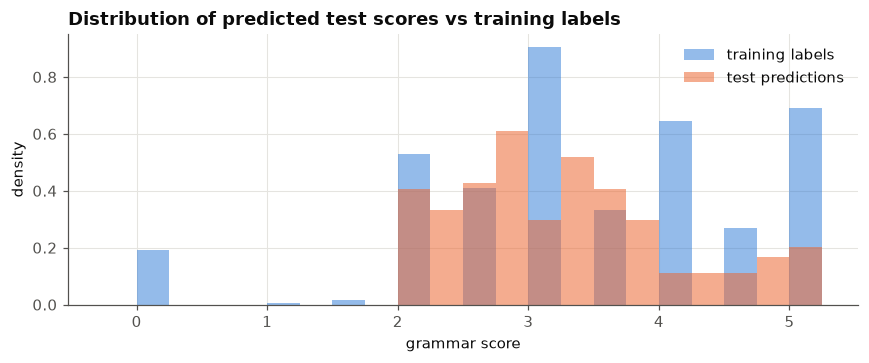

In [19]:
sub = pd.DataFrame({"filename": v2["te"]["filename"], "label": v2["final_test"]})
test_csv = pd.read_csv(DATA_DIR / "test.csv")
assert len(sub) == 216 and set(sub["filename"]) == set(test_csv["filename"])      # one row per test clip
assert sub["label"].between(0, 5).all() and sub["label"].notna().all()            # valid scores
sub.to_csv(V2_OUT / "submission_notebook_v2.csv", index=False)

uploaded = pd.read_csv(V2_OUT / "submission_v2.csv")
print(f"rows: {len(sub)} | columns: {list(sub.columns)}")
print("max |difference| to the file uploaded to Kaggle (outputs/v2/submission_v2.csv):",
      float(np.abs(uploaded.set_index("filename")["label"] - sub.set_index("filename")["label"]).max()))
display(sub.head())

fig, ax = plt.subplots(figsize=(8, 3.4))
edges = np.arange(-0.25, 5.5, 0.25)
ax.hist(tr_meta["label"], bins=edges, density=True, color=BLUE, alpha=0.5, label="training labels")
ax.hist(sub["label"], bins=edges, density=True, color=ORANGE, alpha=0.55, label="test predictions")
ax.set(title="Distribution of predicted test scores vs training labels", xlabel="grammar score", ylabel="density"); ax.legend()
plt.tight_layout(); savefig(fig, "test_distribution"); plt.show()

### Result
submission_v2.csv scored 0.3400 on the public leaderboard. The first submission (v1) scored 0.3540, so this is about 4% better, which is close to the gain seen in cross-validation (0.5355 to 0.5110 test-weighted).

## 6. What did not help, and limitations
These were tested and left out because they did not improve the held-out-prompt CV: a separate stacker per batch, one SVR on all features, an extra model on error-type counts, HuBERT and wav2vec2 next to WavLM, and a 3B language model instead of the 1.5B one. DeBERTa-v3-large instead of base was a little better in CV but scored 0.3427 on the public leaderboard, so it was not used.

The dataset is small (769 clips) and the human scores are noisy. Most of the remaining error is on the 45 s clips, whose prompts are mostly missing from train.

## 7. Reproducing

In [20]:
import importlib.metadata as md_
versions = {p: md_.version(p) for p in ["torch", "transformers", "faster-whisper", "scikit-learn", "lightgbm", "numpy", "pandas", "joblib"]}
print("python", platform.python_version(), "|", ", ".join(f"{k} {v}" for k, v in versions.items()))
print("seed:", SEED, "| folds:", N_FOLDS, "| GPU used for the cached features: NVIDIA RTX 3050 Laptop (4 GB)")

python 3.13.7 | torch 2.11.0+cu128, transformers 5.17.0, faster-whisper 1.2.1, scikit-learn 1.9.1, lightgbm 4.7.0, numpy 2.5.3, pandas 3.0.6, joblib 1.6.0
seed: 42 | folds: 5 | GPU used for the cached features: NVIDIA RTX 3050 Laptop (4 GB)


To rerun everything from scratch: install requirements.txt, put the dataset in data/Dataset_Final, set RUN_HEAVY = True and run all cells (about 3 hours on a 4 GB GPU). The same steps exist as scripts: src/ for the v1 features, then src_v2/run_all.py.